<a href="https://colab.research.google.com/github/TreesaAbraham/svd-image-compression-MATH344L/blob/main/notebook/02_svd_approximation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#Milestone 2: The SVD and Rank-k Approximation

In [2]:
#load the image
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
A = data.camera().astype(float)
print(A.shape, A.dtype)

(512, 512) float64


The above code loads in the grayscale image and convert to float64

In [3]:
# Compute and check the SVD
#splits the matrix into U(512x512) with orthonormal columns, s an array of 512 numbers, and Vt the transpose of U
#A_back multiples the pieces back together, and the prints confirm if it was built and the largest error

U, s, Vt = np.linalg.svd(A, full_matrices=False)
print("U:", U.shape, "s:", s.shape, "Vt:", Vt.shape)

A_back = U @ np.diag(s) @ Vt
print("Rebuilt correctly?", np.allclose(A, A_back))
print("Largest error:", np.abs(A - A_back).max())

U: (512, 512) s: (512,) Vt: (512, 512)
Rebuilt correctly? True
Largest error: 2.538058652135078e-11


The above code splits the matrix into an orthogonal matrix U, an array S (with one dimension), and V transpose, where multiplying these again will get the original matrix back with a small rounding error

First five: [70966.  17054.6 13314.9  8837.4  5874.6]
50th, 200th, last: 757.2 175.5 0.006


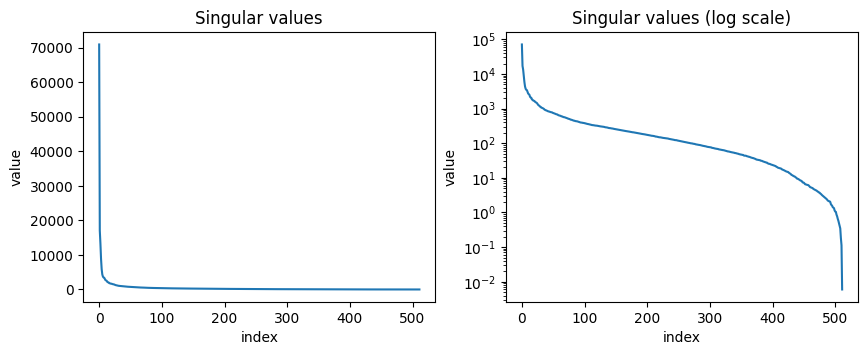

In [4]:
# Inspect the singular values
#print the largest singular values, then print the 50th, 200th, and last values
print("First five:", np.round(s[:5], 1))
print("50th, 200th, last:", round(s[49], 1),
round(s[199], 1), round(s[-1], 3))
#axl1 plots the values on a regular linear axis, Fast decay show low-rank approximation A_k works well
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.plot(s)
ax1.set(title="Singular values", xlabel="index", ylabel="value")
#axl2 plots the points on a log scale, steep drop (main structure/brightness), long slope (fine details), last value (0.006)->large drop
ax2.semilogy(s)
ax2.set(title="Singular values (log scale)", xlabel="index", ylabel="value")
plt.show()

The above code and graphs show that the singular values decay very quickly so that it is a good candidate for compression

In [5]:
# Make a rank-k approximation
  # Return the rank-k SVD approximation of A. U: a matrix with left singular vectors, s: 1-d array of singular values, Vt: V transpose
#U[:, :k] keeps the first k columns of U; s[:k] keeps the first k singular values; and Vt[:k, :] keeps the first k rows of V tranpose
def rank_k_approx(A, k):
  U, s, Vt = np.linalg.svd(A, full_matrices=False)
  return U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]


The above code creates the function with the description as given

In [6]:
#A10 has rank 10, A reconstructs the photo, and the rank 1 strips has only one nonzero singular value
print("rank of A_10:", np.linalg.matrix_rank(rank_k_approx(A, 10)))
print("k = 512 gives A back?", np.allclose(rank_k_approx(A, 512), A))
stripes = np.outer([1, 0, 1, 0], [1, 1, 1, 1]).astype(float)
print("singular values of stripes:",
np.round(np.linalg.svd(stripes, compute_uv=False), 4))

rank of A_10: 10
k = 512 gives A back? True
singular values of stripes: [2.8284 0.     0.     0.    ]


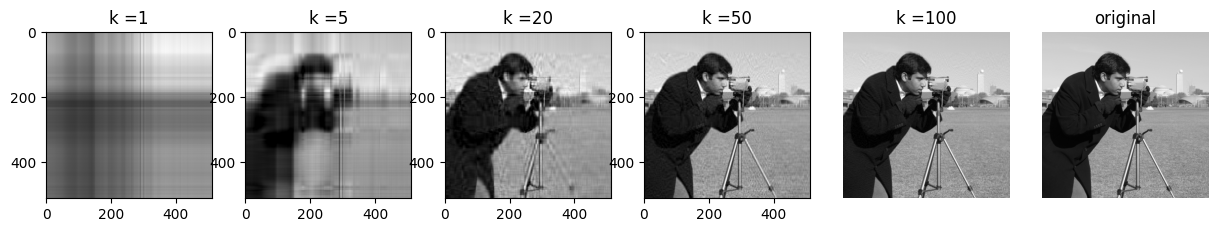

In [11]:
# Compare compressed images
#make a list of ks to try, and make a row of plots
ks = [1, 5, 20, 50, 100]
fig, axes = plt.subplots(1, len(ks) + 1, figsize=(15, 3))
#build each rank-k image, then display the matrix as a grayscale picture
for ax, k in zip(axes, ks):
  Ak = np.clip(rank_k_approx(A, k), 0, 255)
  ax.imshow(Ak, cmap="gray", vmin=0, vmax=255)
  ax.set_title(f"k ={k}")

ax.axis("off")
axes[-1].imshow(A, cmap="gray", vmin=0, vmax=255)
axes[-1].set_title("original")
axes[-1].axis("off")
plt.show()

This builds back the images. As k increases from 1 to 100, the imae gets closer and closer to the original image.

In [8]:
#practice exercise 1
M=np.array([[3,0], [4,5]])
MtM=M.T@M
eigvals = np.linalg.eigvalsh(MtM)
print(eigvals)
sing_from_eig = np.sqrt(eigvals)[::-1]
print(sing_from_eig)
U_exercise, s_exercise, Vt_excercise = np.linalg.svd(M)
print("U: {}, s: {}, Vt{}".format(U_exercise, s_exercise, Vt_excercise))
print(np.allclose(sing_from_eig, s_exercise))

u1 = U_exercise[:, 0]
v1 = Vt_excercise[0, :]
print("u1 v1^T unchanged after flipping both?",
      np.allclose(np.outer(u1, v1), np.outer(-u1, -v1)))
#simultaneous sign changes in u1 and v1 leave u1vT1 unchanged because each entry is a negative times negative, so the minus signs cancel

[ 5. 45.]
[6.70820393 2.23606798]
U: [[-0.31622777 -0.9486833 ]
 [-0.9486833   0.31622777]], s: [6.70820393 2.23606798], Vt[[-0.70710678 -0.70710678]
 [-0.70710678  0.70710678]]
True
u1 v1^T unchanged after flipping both? True


In [9]:

#practice exercise 2
camera=np.linalg.norm(A - rank_k_approx(A, 20))
print(camera)
k_20=np.sqrt(np.sum(s[20:]**2))
print(k_20)
print(np.allclose(camera, k_20))
#the slice at 20 uses the singular values  not used in the rank_20 approximation, they are used to compare the error caused by dropping the last 492 values

7699.9091419681245
7699.9091419681245
True
